# CASMI 2026 — Import avec KaggleHub et visualisation rapide

Ce notebook télécharge les données de la compétition dans `kaggle/input/`, puis permet une exploration légère sans charger tout `train.parquet` en mémoire.


## 1. Installer les dépendances

In [2]:
%pip install -q -U kagglehub pyarrow pandas matplotlib ipywidgets rdkit scikit-learn


Note: you may need to restart the kernel to use updated packages.


## 2. Imports et dossier de destination

In [3]:
from pathlib import Path
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

COMPETITION = "enveda-CASMI26-molecule-id-mass-spectra"
DATA_DIR = Path("kaggle/input").resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier de destination :", DATA_DIR)


Dossier de destination : /home/antonin/Projects/Kaggle_Compet/projet_ml/kaggle/input


## 3. Authentification Kaggle

Si KaggleHub te demande de t’authentifier, décommente la ligne suivante. Tu dois aussi avoir accepté les règles de la compétition sur Kaggle.

In [4]:
# login() est interactif : on ne le lance que si les données doivent être téléchargées
if not (DATA_DIR / "train.parquet").exists():
    kagglehub.login()

## 4. Télécharger les données dans `kaggle/input/`

In [5]:
TRAIN_PATH = DATA_DIR / "train.parquet"

if TRAIN_PATH.exists():
    print("Les données sont déjà présentes, téléchargement ignoré.")
else:
    downloaded_path = kagglehub.competition_download(
        COMPETITION,
        output_dir=str(DATA_DIR)
    )
    print("Téléchargement terminé :", downloaded_path)

print("\nFichiers présents :")
for p in sorted(DATA_DIR.iterdir()):
    if p.is_file():
        print(f"- {p.name:35s} {p.stat().st_size / 1024**3:.2f} Go")


Les données sont déjà présentes, téléchargement ignoré.

Fichiers présents :
- sample_submission.csv               0.00 Go
- test.parquet                        0.00 Go
- train.parquet                       2.82 Go


## 5. Définir les chemins

In [6]:
TRAIN_PATH = DATA_DIR / "train.parquet"
TEST_PATH = DATA_DIR / "test.parquet"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

print("TRAIN_PATH      =", TRAIN_PATH)
print("TEST_PATH       =", TEST_PATH)
print("SUBMISSION_PATH =", SUBMISSION_PATH)

assert TRAIN_PATH.exists(), "train.parquet introuvable"
assert TEST_PATH.exists(), "test.parquet introuvable"
assert SUBMISSION_PATH.exists(), "sample_submission.csv introuvable"


TRAIN_PATH      = /home/antonin/Projects/Kaggle_Compet/projet_ml/kaggle/input/train.parquet
TEST_PATH       = /home/antonin/Projects/Kaggle_Compet/projet_ml/kaggle/input/test.parquet
SUBMISSION_PATH = /home/antonin/Projects/Kaggle_Compet/projet_ml/kaggle/input/sample_submission.csv


## 6. Inspecter `train.parquet` sans le charger entièrement

In [7]:
train_file = pq.ParquetFile(TRAIN_PATH)

print(f"Nombre de lignes     : {train_file.metadata.num_rows:,}")
print(f"Nombre de colonnes   : {train_file.metadata.num_columns}")
print(f"Nombre de row groups : {train_file.num_row_groups}")

print("\nColonnes :")
for col in train_file.schema.names:
    print("-", col)

print(train_file.schema_arrow.names)


Nombre de lignes     : 2,539,608
Nombre de colonnes   : 18
Nombre de row groups : 21

Colonnes :
- ingest_lib
- normalized_smiles
- inchikey
- inchikey14
- molecular_formula
- ionization_mode
- instrument_type
- adduct
- adduct_orig
- precursor_mz
- precursor_error_ppm
- element
- element
- num_peaks
- base_peak_intensity
- element
- collision_energy_orig
- collision_energy_orig_units
['ingest_lib', 'normalized_smiles', 'inchikey', 'inchikey14', 'molecular_formula', 'ionization_mode', 'instrument_type', 'adduct', 'adduct_orig', 'precursor_mz', 'precursor_error_ppm', 'ms2_mzs', 'ms2_normalized_intensities', 'num_peaks', 'base_peak_intensity', 'collision_energy_ev', 'collision_energy_orig', 'collision_energy_orig_units']


## 7. Résumé des colonnes sur tout le train

Les métadonnées parquet contiennent le nombre de valeurs manquantes par colonne et par row group : on obtient le résumé exact sur les 2,5 M de spectres sans rien charger.


In [8]:
n_rows = train_file.metadata.num_rows
null_counts = pd.Series(0, index=train_file.schema_arrow.names)

for i in range(train_file.num_row_groups):
    rg = train_file.metadata.row_group(i)
    for j in range(rg.num_columns):
        col = rg.column(j)
        # "ms2_mzs.list.element" -> "ms2_mzs"
        null_counts[col.path_in_schema.split(".")[0]] += col.statistics.null_count

summary = pd.DataFrame({
    "type": [str(field.type) for field in train_file.schema_arrow],
    "nb_manquants": null_counts,
    "pct_manquants": (null_counts / n_rows * 100).round(2)
})

display(summary)

,type,nb_manquants,pct_manquants
ingest_lib,string,0,0.00
normalized_smiles,string,0,0.00
inchikey,string,0,0.00
inchikey14,string,0,0.00
molecular_formula,string,0,0.00
ionization_mode,string,0,0.00
instrument_type,string,33053,1.30
adduct,string,0,0.00
adduct_orig,string,0,0.00
precursor_mz,double,0,0.00


## 8. Charger un petit échantillon

In [9]:
train = train_file.read_row_group(0).to_pandas()

MAX_ROWS = 10_000
if len(train) > MAX_ROWS:
    train = train.sample(MAX_ROWS, random_state=42).reset_index(drop=True)

print("Échantillon chargé :", train.shape)
display(train.head())


Échantillon chargé : (10000, 18)


,ingest_lib,normalized_smiles,inchikey,inchikey14,molecular_formula,ionization_mode,instrument_type,adduct,adduct_orig,precursor_mz,precursor_error_ppm,ms2_mzs,ms2_normalized_intensities,num_peaks,base_peak_intensity,collision_energy_ev,collision_energy_orig,collision_energy_orig_units
0,enveda-180,CCn1cnnc1CNC(C)c1ccc(C)c(C)c1,BQWBVDMVRLJQFZ-UHFFFAOYSA-N,BQWBVDMVRLJQFZ,C15H22N4,positive,timsTOF,[M+H]+,[M+H]+,259.1922,0.265282,"[20.4231, 21.2053, 21.7418, 22.787, 23.0086, 2...","[0.01756311745334797, 0.021441639224295646, 0....",288,13665.0,[60.0],60,eV
1,enveda-180,O=C(NCc1cn2cc(Cl)ccc2n1)C1CC12CCNCC2,AIVSEVACPOBPOX-UHFFFAOYSA-N,AIVSEVACPOBPOX,C16H19ClN4O,positive,timsTOF,[M+H]+,[M+H]+,319.1328,0.802287,"[65.0385, 66.0466, 66.0485, 67.0402, 67.0427, ...","[0.010952040085898354, 0.006714387974230494, 0...",215,69850.0,[60.0],60,eV
2,enveda-180,CS(=O)(=O)NCCNC(=O)c1ccc(-c2ccccc2)cc1,BQIDDWAIIYDGLH-UHFFFAOYSA-N,BQIDDWAIIYDGLH,C16H18N2O3S,positive,timsTOF,[2M+Na]+,[2M+Na]+,659.1983,1.359946,"[97.0618, 97.0637, 117.0544, 144.0439, 159.065...","[0.006385466318913571, 0.005935785592229517, 0...",47,11119.0,[60.0],60,eV
3,enveda-180,CCc1nsc(NCC2CC(=O)N(CCOC)C2c2cnn(C)c2C)n1,AMLYPHULGQZKSN-UHFFFAOYSA-N,AMLYPHULGQZKSN,C17H26N6O2S,positive,timsTOF,[M+H]+,[M+H]+,379.1921,1.259756,"[65.0367, 65.0395, 66.0341, 67.0402, 67.0419, ...","[0.0007039615207985884, 0.0004048534068112054,...",787,330984.0,"[20.0, 40.0, 60.0]","20,40,60",eV
4,enveda-180,O=C(Cn1cc(Cl)cn1)Nc1ccc2c(c1)OCO2,CKJWUVNIBDTIET-UHFFFAOYSA-N,CKJWUVNIBDTIET,C12H10ClN3O3,positive,timsTOF,[M+H]+,[M+H]+,280.0484,1.824358,"[62.0159, 62.9809, 65.039, 65.0421, 65.0445, 6...","[0.007517619420516836, 0.01456538762725137, 0....",73,6385.0,[60.0],60,eV


## Résumé de adduct

In [10]:
adduct_summary = (
    train["adduct"]
    .value_counts(dropna=False)
    .to_frame("count")
)

adduct_summary["percent"] = (
    adduct_summary["count"] / len(train) * 100
).round(2)

display(adduct_summary)

,count,percent
adduct,,
[M+H]+,5199,51.99
[M-H]-,1585,15.85
[2M+Na]+,1530,15.30
[2M+H]+,732,7.32
[2M-H]-,463,4.63
[M+CH2O2-H]-,225,2.25
[M+Na]+,152,1.52
[M+NH4]+,53,0.53
[M+K]+,28,0.28


## Visualisation plus précise des na

In [11]:
cols_na = [
    "instrument_type",
    "base_peak_intensity",
    "collision_energy_ev",
    "collision_energy_orig"
]

train[cols_na].isna().sum()
train[cols_na].isna().all(axis=1).sum() == \
train[cols_na].isna().any(axis=1).sum()

np.True_

In [12]:
mask_na = train[cols_na].isna().all(axis=1)

pd.crosstab(
    train["ingest_lib"],
    mask_na,
    normalize="index"
) * 100

col_0,False,True
ingest_lib,,
drug_plus,0.0,100.0
enveda-180,100.0,0.0


In [13]:
na_by_library = (
    train
    .assign(metadata_missing=mask_na)
    .groupby("ingest_lib")
    .agg(
        n=("ingest_lib", "size"),
        n_missing=("metadata_missing", "sum"),
        pct_missing=("metadata_missing", "mean")
    )
)

na_by_library["pct_missing"] *= 100

display(
    na_by_library.sort_values("pct_missing", ascending=False)
)

,n,n_missing,pct_missing
ingest_lib,,,
drug_plus,215,215,100.0
enveda-180,9785,0,0.0


## 9. Visualiser un spectre MS/MS

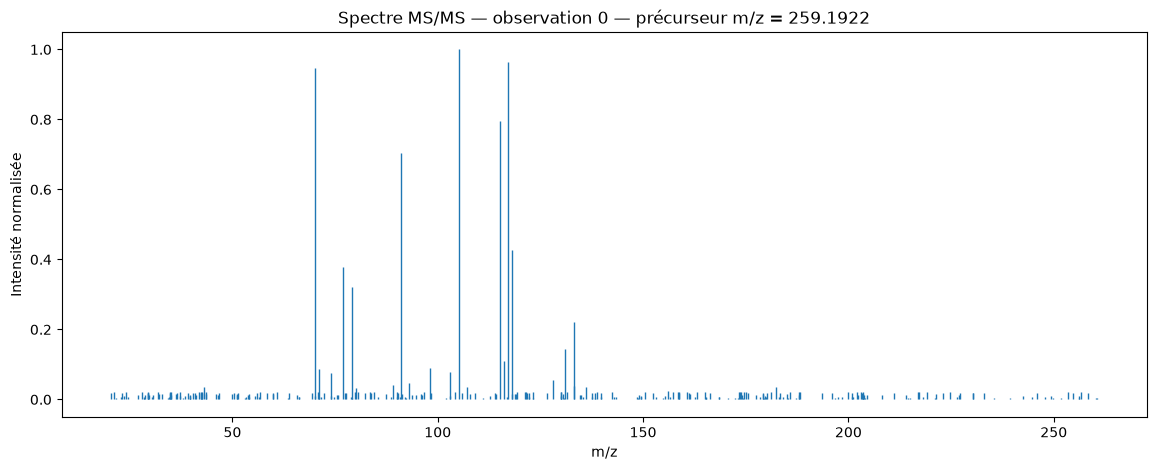

In [14]:
ROW_ID = 0
row = train.iloc[ROW_ID]

mzs = np.asarray(row["ms2_mzs"], dtype=float)
intensities = np.asarray(row["ms2_normalized_intensities"], dtype=float)

plt.figure(figsize=(14, 5))
plt.vlines(mzs, 0, intensities, linewidth=1)
plt.xlabel("m/z")
plt.ylabel("Intensité normalisée")

title = f"Spectre MS/MS — observation {ROW_ID}"
if "precursor_mz" in train.columns:
    title += f" — précurseur m/z = {row['precursor_mz']}"
plt.title(title)
plt.show()


## 10. Voir les pics les plus intenses

In [15]:
peaks = (
    pd.DataFrame({"mz": mzs, "intensity": intensities})
    .sort_values("intensity", ascending=False)
    .reset_index(drop=True)
)

display(peaks.head(20))


,mz,intensity
0,105.0704,1.000000
1,117.0704,0.963557
2,70.0412,0.946506
3,115.0551,0.794292
4,91.0551,0.703549
5,118.0765,0.428394
6,77.0387,0.379437
7,79.0553,0.322430
8,133.1006,0.221442
9,131.0843,0.143578


## 11. Afficher la molécule correspondante avec RDKit

SMILES : CCn1cnnc1CNC(C)c1ccc(C)c(C)c1


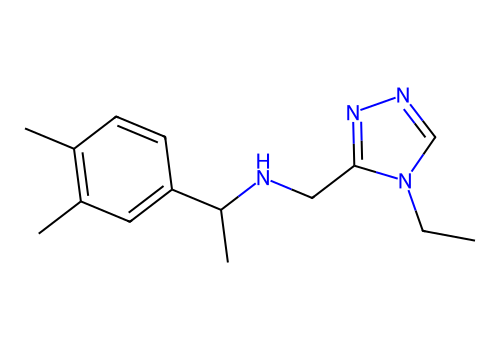

In [16]:
if "normalized_smiles" in train.columns:
    try:
        from rdkit import Chem
        from rdkit.Chem import Draw

        smiles = row["normalized_smiles"]
        print("SMILES :", smiles)
        mol = Chem.MolFromSmiles(smiles)

        if mol is not None:
            display(Draw.MolToImage(mol, size=(500, 350)))
        else:
            print("SMILES non interprétable par RDKit.")
    except ImportError:
        print("RDKit n’est pas installé dans cet environnement.")


## 12. Examiner rapidement le test

In [17]:
test_file = pq.ParquetFile(TEST_PATH)

print(f"Nombre de lignes test   : {test_file.metadata.num_rows:,}")
print(f"Nombre de colonnes test : {test_file.metadata.num_columns}")

test = test_file.read_row_group(0).to_pandas().head()
display(test)


Nombre de lignes test   : 1,213
Nombre de colonnes test : 12


,molecule_id,spectrum_id,ms2_mzs,ms2_normalized_intensities,base_peak_intensity,adduct,ionization_mode,instrument_type,precursor_mz,collision_energy_orig,collision_energy_ev,collision_energy_orig_units
0,m_005e53,s_4d19d522,"[67.0414, 73.0074, 74.0142, 74.0174, 75.0238, ...","[0.0016501163269310492, 0.0004909040749095276,...",2711324.0,[M+H]+,positive,timsTOF,375.0709,"20,40,60","[20.0, 40.0, 60.0]",eV
1,m_005e53,s_5b6e28ff,"[67.0414, 73.0074, 74.0174, 75.0236, 76.0311, ...","[0.0029581573469943693, 0.0008800418929033316,...",1512428.0,[M+H]+,positive,timsTOF,375.0709,40,[40.0],eV
2,m_005e53,s_6e514292,"[74.0142, 75.0238, 76.0313, 77.0357, 77.0398, ...","[0.0071407135863519105, 0.009720343101840298, ...",989677.0,[M+H]+,positive,timsTOF,375.0709,60,[60.0],eV
3,m_005e53,s_855ae19c,"[42.9863, 45.6701, 69.5715, 78.9191, 78.929, 7...","[0.0014297061159650516, 0.0014297061159650516,...",6295.0,[M-H]-,negative,timsTOF,373.0562,-60,[60.0],eV
4,m_006153,s_3c74e9fe,"[65.0391, 77.0385, 77.1154, 78.0479, 85.0515, ...","[0.000254435863675019, 0.0009782620275780901, ...",3191374.0,[M+H]+,positive,timsTOF,342.1569,20,[20.0],eV


## 13. Voir le format de soumission

In [18]:
sample_submission = pd.read_csv(SUBMISSION_PATH)
print("Dimensions :", sample_submission.shape)
display(sample_submission.head())


Dimensions : (400, 2)


,molecule_id,smiles
0,m_005e53,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
1,m_006153,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
2,m_00b5aa,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
3,m_01e922,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
4,m_0259d4,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...


## 14. Charger tout le train si nécessaire

Seulement si tu as assez de RAM :

```python
train_full = pd.read_parquet(TRAIN_PATH)
```

Pour l’EDA initiale, l’échantillon avec `pyarrow` est préférable.


In [19]:
print(len(train))
print(train_file.metadata.num_rows)

10000
2539608


## Passage sur le vrai dataset meta

### Visualisation de meta

In [20]:
meta = pd.read_parquet(
    TRAIN_PATH,
    columns=[
        "inchikey14",
        "normalized_smiles",
        "molecular_formula",
        "ingest_lib",
        "ionization_mode",
        "adduct",
        "precursor_mz",
        "precursor_error_ppm",
        "instrument_type",
        "num_peaks",
        "base_peak_intensity",
        "collision_energy_ev"
    ]
)

print(meta.shape)

(2539608, 12)


In [21]:
print("Spectres :", len(meta))
print("Molécules :", meta["inchikey14"].nunique())

display(meta["ingest_lib"].value_counts())
display(meta["adduct"].value_counts(dropna=False))
display(meta["ionization_mode"].value_counts(dropna=False))

display(
    meta.groupby("inchikey14")
        .size()
        .describe()
)

Spectres : 2539608
Molécules : 275810


ingest_lib
enveda-180            1153785
pluskal_ms2            527581
riken                  347171
gnps                   220849
massbank               101727
mona                    92416
spectraverse            50933
msdial                  40765
drug_plus                2545
enveda-np-examples       1184
masaryk                   652
Name: count, dtype: int64

adduct
[M+H]+         1324585
[M-H]-          465688
[2M+Na]+        190033
[M+Na]+         178092
[2M+H]+          92041
                ...   
[M-CH3O]+            1
[2M-H5O3]+           1
[M+C2H7OS]+          1
[M+HO]+              1
[3M+K]+              1
Name: count, Length: 121, dtype: int64

ionization_mode
positive    1899640
negative     639968
Name: count, dtype: int64

count    275810.000000
mean          9.207817
std          21.069560
min           1.000000
25%           4.000000
50%           6.000000
75%           9.000000
max        1468.000000
dtype: float64

# Création d'un dictionnaire de masse monoisotopique

## Fonction de calcul masse de la molécule neutre

In [22]:
import re
from rdkit import Chem

ELECTRON_MASS = 0.000548579909065
PERIODIC_TABLE = Chem.GetPeriodicTable()


def get_atom_mass(symbol):
    """
    Retourne la masse monoisotopique de l'élément.
    """
    atomic_number = PERIODIC_TABLE.GetAtomicNumber(symbol)

    if atomic_number == 0:
        raise ValueError(f"Atome inconnu : {symbol}")

    return PERIODIC_TABLE.GetMostCommonIsotopeMass(atomic_number)


def formula_mass(formula):
    """
    Calcule la masse d'une formule chimique.

    Exemples :
    H       -> masse de H
    H2O     -> 2*H + O
    C4H11O2 -> 4*C + 11*H + 2*O
    2H2O    -> 2 * (2*H + O)
    """

    # coefficient devant toute la formule, puis uniquement des blocs Élément+nombre
    # ("Cat" n'est plus accepté silencieusement)
    match = re.fullmatch(r"(\d*)((?:[A-Z][a-z]?\d*)+)", formula)

    if match is None:
        raise ValueError(f"Formule non reconnue : {formula}")

    global_coef = int(match.group(1)) if match.group(1) else 1

    # Ex. C4H11O2 -> [('C','4'), ('H','11'), ('O','2')]
    elements = re.findall(r"([A-Z][a-z]?)(\d*)", match.group(2))

    mass = 0.0

    for symbol, count in elements:
        count = int(count) if count else 1
        mass += get_atom_mass(symbol) * count

    return global_coef * mass


def parse_adduct(adduct):
    """
    Décompose un adduct en (coeff_mol, relative_sum, z).

    Exemples supportés :
    [M+H]+, [M-H]-, [M-C4H11O2]+, [2M+Ca-H]+, [M-2H2O+H]+, [M-2H]2-

    Lève ValueError si l'adduct n'est pas interprétable (ex. [Cat]2+).
    """

    match = re.fullmatch(r"\[(.+)\](\d*)([+-])", adduct.strip())

    if match is None:
        raise ValueError(f"Adduct invalide : {adduct}")

    inside, charge_str, sign_str = match.groups()

    # Ex : "2M+Ca-H" -> ["2M", "+Ca", "-H"]
    parts = re.findall(r"[+-]?[^+-]+", inside)

    # Nombre de molécules M
    m_match = re.fullmatch(r"(\d*)M", parts[0])

    if m_match is None:
        raise ValueError(f"Premier bloc non reconnu comme M : {parts[0]}")

    coeff_mol = int(m_match.group(1)) if m_match.group(1) else 1

    # Masse des ajouts / pertes
    relative_sum = 0.0

    for part in parts[1:]:
        sign = -1 if part.startswith("-") else +1
        relative_sum += sign * formula_mass(part.lstrip("+-"))

    # Charge : ]+ -> +1, ]2+ -> +2, ]- -> -1 ...
    charge_magnitude = int(charge_str) if charge_str else 1
    z = charge_magnitude * (1 if sign_str == "+" else -1)

    return coeff_mol, relative_sum, z


def get_neutral_mass(precursor_mz, adduct):
    """
    Calcule la masse neutre M à partir du precursor_mz et de l'adduct.
    Renvoie NaN si l'adduct n'est pas interprétable.
    """

    try:
        coeff_mol, relative_sum, z = parse_adduct(adduct)
    except (ValueError, TypeError, AttributeError):
        return np.nan

    ion_mass = abs(z) * precursor_mz

    return (ion_mass - relative_sum + z * ELECTRON_MASS) / coeff_mol


def compute_neutral_masses(df):
    """
    Version vectorisée pour un DataFrame (colonnes adduct, precursor_mz) :
    chaque adduct distinct n'est parsé qu'une seule fois.
    """

    params = {}

    for adduct in df["adduct"].dropna().unique():
        try:
            params[adduct] = parse_adduct(adduct)
        except ValueError:
            params[adduct] = (np.nan, np.nan, np.nan)

    p = (
        pd.DataFrame(params, index=["coeff_mol", "relative_sum", "z"])
        .T
        .reindex(df["adduct"])
    )

    coeff = p["coeff_mol"].to_numpy(dtype=float)
    rel = p["relative_sum"].to_numpy(dtype=float)
    z = p["z"].to_numpy(dtype=float)

    return (np.abs(z) * df["precursor_mz"].to_numpy() - rel + z * ELECTRON_MASS) / coeff

### Tests rapides

In [23]:
tests = [
    "[M+H]+",
    "[M-H]-",
    "[M-C4H11O2]+",
    "[M-H5O3]+",
    "[2M+Ca-H]+",
    "[M-2H2O+H]+",
    "[M-2H]2-",
    "[Cat]2+",  # doit renvoyer NaN
]

for adduct in tests:
    mass = get_neutral_mass(500.0, adduct)
    print(f"{adduct:20s} -> {mass:.6f}")

assert np.isclose(get_neutral_mass(500.0, "[M+H]+"), 498.992724, atol=1e-6)
assert np.isnan(get_neutral_mass(500.0, "[Cat]2+"))

[M+H]+               -> 498.992724
[M-H]-               -> 501.007276
[M-C4H11O2]+         -> 591.076453
[M-H5O3]+            -> 553.024418
[2M+Ca-H]+           -> 230.522891
[M-2H2O+H]+          -> 535.013853
[M-2H]2-             -> 1002.014553
[Cat]2+              -> nan


### Masse neutre sur tout `meta`

In [24]:
meta["neutral_mass"] = compute_neutral_masses(meta)

print("Spectres sans masse neutre :", meta["neutral_mass"].isna().sum())
display(meta.loc[meta["neutral_mass"].isna(), "adduct"].value_counts())

Spectres sans masse neutre : 15


adduct
[Cat]2+    15
Name: count, dtype: int64

### Vérification contre la masse exacte des SMILES

In [25]:
from rdkit.Chem import Descriptors

# Vérification : masse neutre calculée vs masse exacte du SMILES (échantillon)
check_mass = meta.sample(20_000, random_state=0)[
    ["normalized_smiles", "adduct", "ingest_lib", "neutral_mass"]
].copy()

exact_by_smiles = {
    s: Descriptors.ExactMolWt(Chem.MolFromSmiles(s))
    for s in check_mass["normalized_smiles"].unique()
}

check_mass["exact_mass"] = check_mass["normalized_smiles"].map(exact_by_smiles)
check_mass["mass_error_ppm"] = (
    (check_mass["neutral_mass"] - check_mass["exact_mass"])
    / check_mass["exact_mass"] * 1e6
)
check_mass["ok_20ppm"] = check_mass["mass_error_ppm"].abs() < 20

print(check_mass["mass_error_ppm"].abs().describe())

display(
    check_mass.groupby("ingest_lib")["ok_20ppm"]
    .agg(["mean", "size"])
    .sort_values("mean")
)
display(
    check_mass.groupby("adduct")["ok_20ppm"]
    .agg(["mean", "size"])
    .sort_values("size", ascending=False)
    .head(15)
)

count    2.000000e+04
mean     1.396736e+03
std      2.594024e+04
min      3.049227e-07
25%      1.057694e-01
50%      9.207033e-01
75%      2.299864e+00
max      1.083208e+06
Name: mass_error_ppm, dtype: float64


,mean,size
ingest_lib,,
riken,0.881682,2806
massbank,0.898348,787
mona,0.930295,746
gnps,0.934203,1687
drug_plus,0.954545,22
msdial,0.997085,343
enveda-np-examples,1.000000,3
enveda-180,1.000000,9090
masaryk,1.000000,9


,mean,size
adduct,,
[M+H]+,0.971111,10523
[M-H]-,0.968398,3639
[2M+Na]+,1.000000,1480
[M+Na]+,0.935348,1423
[2M+H]+,1.000000,706
[M+CH2O2-H]-,1.000000,642
[M+NH4]+,0.961538,416
[2M-H]-,0.997561,410
[M+Cl]-,0.995349,215


# Construction du jeu de validation (hold-out)


On veut construire le set de validation en séparant le train et val sans molécule en commun

In [31]:
molecules = meta["inchikey14"].unique()

print("Spectres : ", len(meta))
print("Molécules :", len(molecules))

Spectres :  2539608
Molécules : 275810


Tirage des molécules

In [33]:
#graine fixée
rng = np.random.default_rng(42)

# 10% des molécules en validation (int() autour du produit : size doit être un entier)
n_val = int(len(molecules) * 0.10)

# on sélectionne les molécules de validation
val_molecules = set(rng.choice(molecules, size=n_val, replace=False))

# On sélectionne les données de validation
meta["is_val"] = meta["inchikey14"].isin(val_molecules)

print(f"Molécules val : {n_val}")
print(f"Spectres val : {meta['is_val'].sum()} ({meta['is_val'].mean():.1%})")

Molécules val : 27581
Spectres val : 250832 (9.9%)
